# **Block 05 assignment**: *neighbours for your towers*

**Name**: Ben Löw

**Matriculation nr.**: 5737500

**Tower sets student id**: 39

**GitHub fork**: https://github.com/loew-b/datascience_env_monit

**FLUXNET tower sites**:

| Site ID | Citation | Access date|
|---------|----------|------------|
| FR-Pue | Joffre, R., Limousin, J., Kempf, J., Ourcival, J., Piquemal, K., Veuillen, L. (2026). Fluxnet Archive Product from Puechabon, 2000-01-01–2026-09-06, FLUXNET, https://hdl.handle.net/11676/zX4eolqNe8xbcMScyT2IQ9XV | 2026-1120 |
| CA-Ca3 | T. Andrew Black (2026), AmeriFlux FLUXNET-1F CA-Ca3 British Columbia - Pole sapling Douglas-fir stand, Ver. v1.3_r1, AmeriFlux AMP, (Dataset). https://doi.org/10.17190/AMF/3027312 | 2026-11-20 |
| AU-Rig | Beringer, J., McHugh, I. (2026): Riggs Creek FLUXNET Release 2026_r1 . Version  2026_r1. Terrestrial Ecosystem Research Network (TERN). (Dataset). | 2026-11-20 |
| CN-Nmn | Li, Y. (2026). Fluxnet Archive Product from Naiman, 2015–2019, FLUXNET, https://hdl.handle.net/11676/0v70myjZ6UGZr9O6hJG55c-t | 2026-11-20 |
| US-Whs | Russ Scott (2026), AmeriFlux FLUXNET-1F US-Whs Walnut Gulch Lucky Hills Shrub, Ver. v1.3_r1, AmeriFlux AMP, (Dataset). https://doi.org/10.17190/AMF/1984574 | 2026-11-20 |

**FLUXNET network**:

Pastorello et al. (2020), Scientific Data 7, 225, https://doi.org/10.1038/s41597-020-0534-3

**Additional datasets**:

| Dataset | Citation | Access date |
|---------|----------|-------------|
| ERA5-Land | Muñoz-Sabater et al. (2021) ESSD 13, 4349–4383, doi:10.5194/essd-13-4349-2021. Contains modified Copernicus Climate Change Service information (2026) | 2026-11-21 |
| WorldClim 2.1 | Fick & Hijmans (2017) Int. J. Climatol. 37, 4302–4315, doi:10.1002/joc.5086 | 2026-11-21 |
| Dheed | Weynants et al. (2025) ESSD 17, 6621, doi:10.5194/essd-17-6621-2025. Data: doi:10.5281/zenodo.14884254 | 2026-11-21 |
| SoilGrids 2.0 (ISRIC) | Poggio et al. (2021) SOIL 7, 217–240, doi:10.5194/soil-7-217-2021 | 2026-11-21 |
| planttraits.earth | Lusk et al. (2026) Nat. Commun. 17, 1203, doi:10.1038/s41467-026-68996-y. Data: doi:10.5281/zenodo.14646322 | 2026-11-21 |
| deadtrees.earth | Mosig et al. (2026) Remote Sens. Environ. 332, 115027, doi:10.1016/j.rse.2025.115027 | 2026-11-21 |
| iNaturalist | iNaturalist contributors, iNaturalist (2026), https://www.inaturalist.org, accessed 21/11/2026 | 2026-11-21 |
| MODIS Terra MOD13Q1 (Collection 6.1) | Didan (2021) MOD13Q1 V061, NASA LP DAAC, doi:10.5067/MODIS/MOD13Q1.061. ORNL DAAC (2018) MODIS Land Product Subsets Web Service, doi:10.3334/ORNLDAAC/1557 | 2026-11-22 |

----------

## 0\) Data import

In [202]:
# ---- Required packages ----
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os

# ---- Working directory ----
proj_dir = Path(os.getcwd()).parent

# ---- static and daily data ----
site_daily = pd.read_csv(proj_dir / 'data/processed/site_daily.csv', parse_dates=['date'])
site_static = pd.read_csv(proj_dir / 'data/processed/site_static.csv')

----------

## 1\) Data

At least 4 datasets for all 5 towers, MODIS NDVI/EVI included

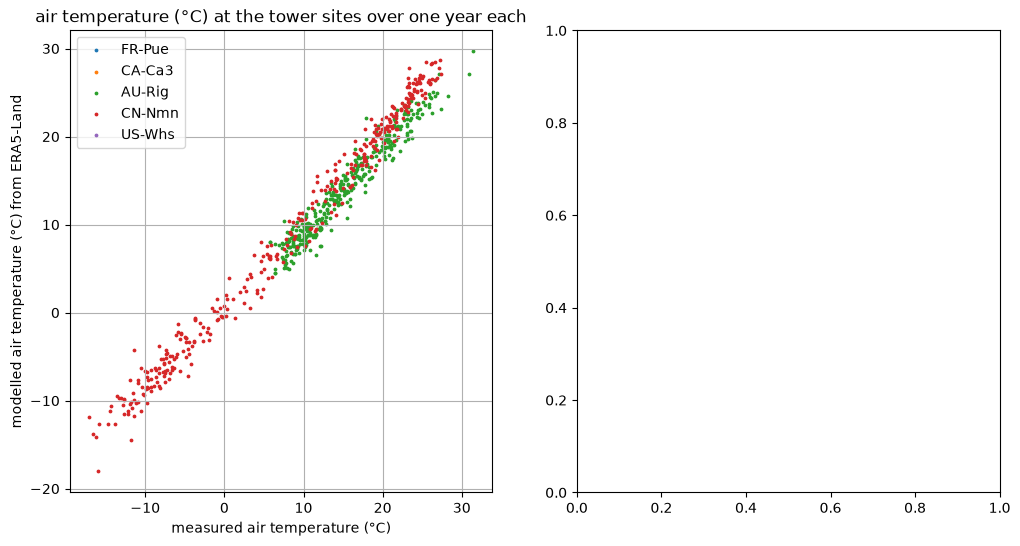

In [88]:
# ---- ERA5-Land ----

fig, ax = plt.subplots(1, 2, figsize=(12,6))

# Check: is ERA5-Land t2m close to the tower's TA_F? Plot one year of both.
for tower in site_static['site_id']:
    ax[0].scatter(
        site_daily['TA_F'][site_daily['site_id'] == tower][0:364], 
        site_daily['era5l_t2m_C'][site_daily['site_id'] == tower][0:364],
        label=tower,
        s=3
    )
del tower
ax[0].set_xlabel('measured air temperature (°C)')
ax[0].set_ylabel('modelled air temperature (°C) from ERA5-Land')
ax[0].grid()
ax[0].set_title('air temperature (°C) at the tower sites over one year each')
ax[0].legend()

# Does GPP drop when the root-zone soil (swvl2, swvl3) dries out?
#Note: couldn't find variables 'swvl2' or 'swvl3'

plt.show()

**Observation**: measured and modelled air temperature seem to be very similar for all selected sites.

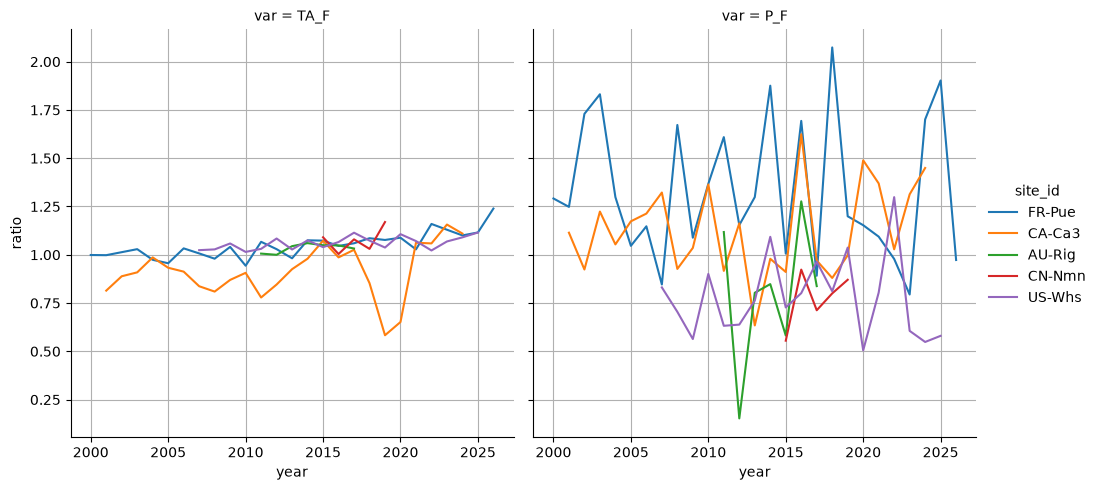

In [199]:
# ---- WorldClim ----
# Compare each tower year's mean TA_F and annual P_F with BIO1 and BIO12. Which of your years were unusually warm or dry?
airtemp_annual = {}
for tower in site_static['site_id']:
    airtemp_annual[tower] = site_daily[site_daily['site_id'] == tower].groupby(site_daily[site_daily['site_id'] == tower]['date'].dt.year)['TA_F'].mean() / site_static['BIO1'][site_static['site_id'] == tower].values

precip_annual = {}
for tower in site_static['site_id']:
    precip_annual[tower] = site_daily[site_daily['site_id'] == tower].groupby(site_daily[site_daily['site_id'] == tower]['date'].dt.year)['P_F'].sum() / site_static['BIO12'][site_static['site_id'] == tower].values

comparison_df = pd.DataFrame({
    'site_id': pd.concat(airtemp_annual).reset_index()['level_0'],
    'year': pd.concat(airtemp_annual).reset_index()['date'],
    'TA_F': pd.concat(airtemp_annual).reset_index()['TA_F'],
    'P_F': pd.concat(precip_annual).reset_index()['P_F']
})
comparison_df = pd.melt(
    comparison_df,
    id_vars=['site_id', 'year'],
    value_vars=['TA_F', 'P_F'],
    value_name='ratio',
    var_name='var'
)

del airtemp_annual
del precip_annual

g = sns.relplot(
    data=comparison_df, x='year', y='ratio',
    hue='site_id', col='var',
    kind='line'
)
for ax in g.axes.flat:
    ax.grid(True)
plt.show()

**Observation**: 2018-2020 were unusually cold at staion 'CA-Ca3'; unusually wet years occurred at site 'FR-Pue' several times, 2012 was unusually dry at site 'AU-Rig', and in 2016, all stations except for 'US-Whs' registered a one-year peak of relative wetness.

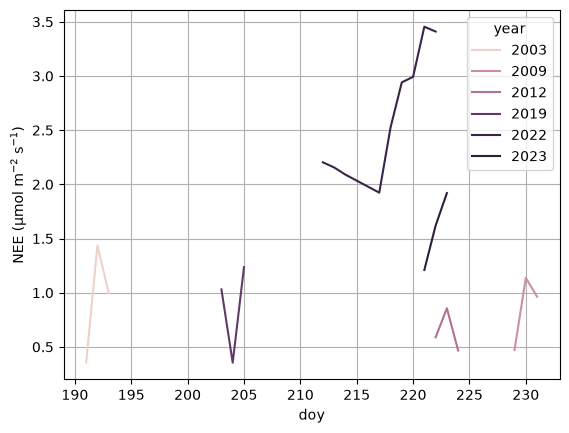

In [173]:
# ---- Dheed ----
# Pick an event at one of your towers. Was NEE less negative than in the same weeks of the other tower years?
dheed = site_daily[(site_daily['dheed_event'] == True) & (site_daily['site_id'] == site_static['site_id'].iloc[0])][['date', 'NEE_VUT_REF']]
dheed['doy'] = dheed['date'].dt.day_of_year
dheed['year'] = dheed['date'].dt.year

sns.lineplot(
    data=dheed,
    x='doy',
    y='NEE_VUT_REF',
    hue='year'
)
plt.grid()
plt.ylabel('NEE ($\\rm \\mu mol~m^{-2}~s^{-1}$)')
plt.show()

**Observation**: unfortunately, there is not really any time of year shared among the years of data available for this tower site when a Dheed event occurs and NEE data is available. For the other sites in this set, NEE coverage is even less for Dheed events. Therefore, the question cannot be properly answered. A week-wise comparison was not conducted here due to difficulties of implementing it.

In [ ]:
# ---- SoilGrids ----
# Do the towers on sandy soils lose GPP faster in a dry spell than towers on clay?


In [ ]:
# ---- PlantTraits ----
# Across all 195 class towers: does leaf N or SLA explain the maximum daily GPP?


In [ ]:
# ---- deadtrees.earth ----
# Forest towers in Europe: did standing deadwood rise after 2018, and did GPP or the GPP/EVI ratio fall with it?
#Note: what is the variable name of standing deadwood?

In [ ]:
# ---- iNaturalist ----
# Phenology from people: in which week do the first flowering plants get photographed near your tower each spring, and does GPP start rising in the same week?


----------

## 2\) Provenance table

Per dataset: source, resolution, period, date accessed, citation

| Dataset | Source | Resolution | Period | Date accessed | Citation |
|---------|--------|------------|--------|---------------|----------|
| ERA5-Land | https://cds.climate.copernicus.eu | 9 km/0.1° | 1950-today | 2026-11-21 | Muñoz-Sabater et al. (2021) ESSD 13, 4349–4383, doi:10.5194/essd-13-4349-2021. Contains modified Copernicus Climate Change Service information (2026) |
| WorldClim 2.1 | https://worldclim.org | 5' | 1970-2000 | 2026-11-21 | Fick & Hijmans (2017) Int. J. Climatol. 37, 4302–4315, doi:10.1002/joc.5086 |
| Dheed | https://doi.org/10.5281/zenodo.14884254 | 0.25°/daily | 1950–2023 | 2026-11-21 | Weynants et al. (2025) ESSD 17, 6621, doi:10.5194/essd-17-6621-2025. Data: doi:10.5281/zenodo.14884254 |
| SoilGrids 2.0 (ISRIC) | https://rest.isric.org | 250 m |  | 2026-11-21 | Poggio et al. (2021) SOIL 7, 217–240, doi:10.5194/soil-7-217-2021 |
| planttraits.earth | https://planttraits.earth | 1 km |  | 2026-11-21 | Lusk et al. (2026) Nat. Commun. 17, 1203, doi:10.1038/s41467-026-68996-y. Data: doi:10.5281/zenodo.14646322 |
| deadtrees.earth | https://deadtrees.earth | 10 m | 2017–2025 | 2026-11-21 | Mosig et al. (2026) Remote Sens. Environ. 332, 115027, doi:10.1016/j.rse.2025.115027 |
| iNaturalist | https://inaturalist.org |  |  | 2026-11-21 | iNaturalist contributors, iNaturalist (2026), https://www.inaturalist.org, accessed 21/11/2026 |
| MODIS Terra MOD13Q1 (Collection 6.1) | https://doi.org/10.5067/MODIS/MOD13Q1.061 | 250 m/16 d | 2000-today |  | Didan (2021) MOD13Q1 V061, NASA LP DAAC, doi:10.5067/MODIS/MOD13Q1.061. ORNL DAAC (2018) MODIS Land Product Subsets Web Service, doi:10.3334/ORNLDAAC/1557 |

----------

## 3\) Site portrait

`site_static` as a table: climate, soil, traits, species records

In [230]:
#Note: the exact assignment seems unclear here. Is a markdown format table required? Which variables should be displayed? 'traits' is a very broad term and could mean any/all variable(s)

var_list = ['BIO1', 'BIO12', 'soil0_30_clay', 'soil0_30_sand', 'soil0_30_silt', 'n_species', 'n_plant_species']

print(round(site_static[var_list].set_index(site_static['site_id']), 2))

          BIO1   BIO12  soil0_30_clay  soil0_30_sand  soil0_30_silt  n_species  n_plant_species
site_id                                                                                        
FR-Pue   13.64   674.0          27.55          30.97          41.45     1055.0            439.0
CA-Ca3    8.99  1532.0          11.12          51.05          37.87      405.0            162.0
AU-Rig   15.15   601.0          20.70          57.98          21.33       27.0             11.0
CN-Nmn    7.17   439.0          18.38          50.95          30.62        NaN              NaN
US-Whs   16.86   376.0          20.78          58.25          20.92      251.0             80.0


**Site portrait**:

| site | BIO1 (°C) | BIO12 (mm) | soil0_30_clay (%) | soil0_30_sand (%) | soil0_30_silt (%) | n_species | n_plant_species |       
|------|-----------|------------|-------------------|-------------------|-------------------|-----------|-----------------|
| FR-Pue | 13.64 | 674.0 | **27.56** | 30.97 | **41.45** | **1055.0** | **439.0** |
| CA-Ca3 | 8.96 | **1532.0** | 11.12 | 51.05 | 37.87 | 405.0 | 162.0 |
| AU-Rig | 15.15 | 601.0 | 20.70 | 57.98 | 21.33 | 27.0 | 11.0 |
| CN-Nmn | 7.17 | 439.0 | 18.38 | 50.95 | 30.62 | `NaN` | `NaN` |
| US-Whs | **16.86** | 376.0 | 20.78 | **58.25** | 20.92 | 251.0 | 80.0 |


----------

## 4\) Time series

NDVI and EVI (yours vs MODIS) with GPP, one panel per tower

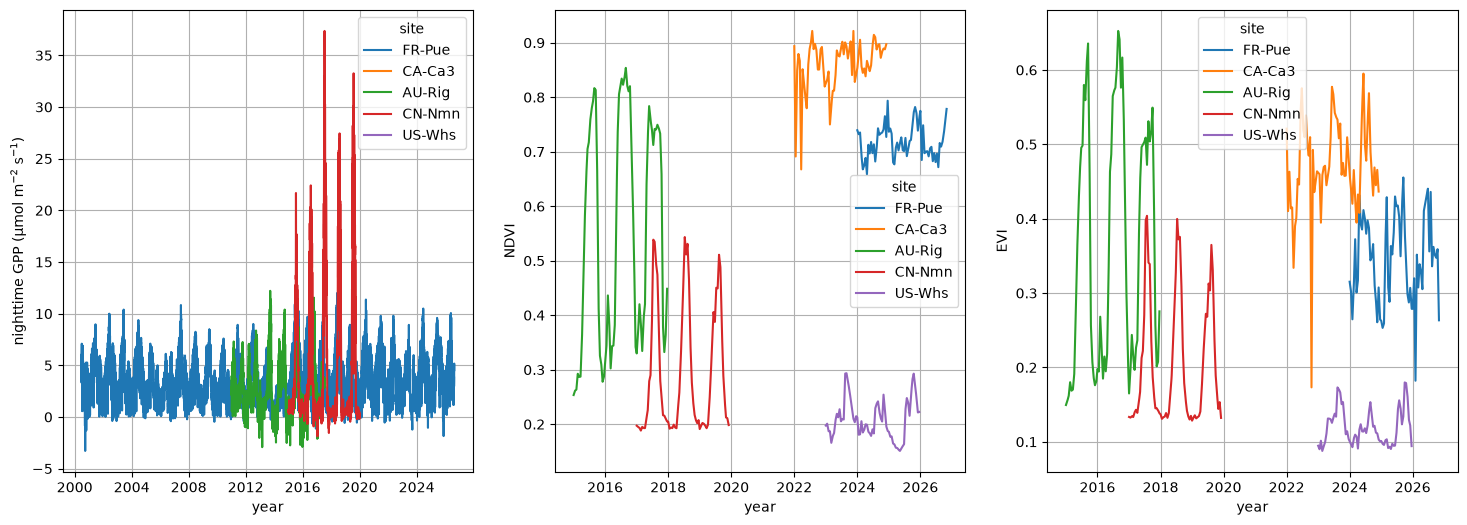

In [198]:
fig, ax = plt.subplots(1, 3, figsize=(18,6))

for tower in site_static['site_id']:
    ax[0].plot(
        site_daily[site_daily['site_id'] == tower]['date'],
        site_daily[site_daily['site_id'] == tower]['GPP_NT_VUT_REF'],
        label=tower
    )
del tower
ax[0].legend(title='site')
ax[0].grid()
ax[0].set_xlabel('year')
ax[0].set_ylabel('nighttime GPP ($\\rm \\mu mol~m^{-2}~s^{-1}$)')

for tower in site_static['site_id']:
    ax[1].plot(
        site_daily[site_daily['site_id'] == tower]['date'],
        site_daily[site_daily['site_id'] == tower]['ndvi'],
        label=tower
    )
del tower
ax[1].legend(title='site')
ax[1].grid()
ax[1].set_xlabel('year')
ax[1].set_ylabel('NDVI')

for tower in site_static['site_id']:
    ax[2].plot(
        site_daily[site_daily['site_id'] == tower]['date'],
        site_daily[site_daily['site_id'] == tower]['evi'],
        label=tower
    )
del tower
ax[2].legend(title='site')
ax[2].grid()
ax[2].set_xlabel('year')
ax[2].set_ylabel('EVI')

plt.show()

**Observation**: unfortunately, there is not a major overlap of GPP and NDVI/EVI data availability. From the limited data, no obvious connection between GPP and NDVI/EVI is visible. NDVI and EVI show fairly similar time series.

----------

## 5\) One question

Pick one of the six; one figure + 5–8 sentences, with n stated

*My question*:

**Greenness and productivity**: Does EVI or NDVI follow GPP through the seasons? Which tower fits best, and when does it break?

GPP/EVI correlation:
site_id
AU-Rig    0.902082
CA-Ca3         NaN
CN-Nmn    0.933476
FR-Pue    0.597968
US-Whs         NaN
dtype: float64
------------------
GPP/NDVI correlation:
site_id
AU-Rig    0.849541
CA-Ca3         NaN
CN-Nmn    0.928845
FR-Pue   -0.378259
US-Whs         NaN
dtype: float64


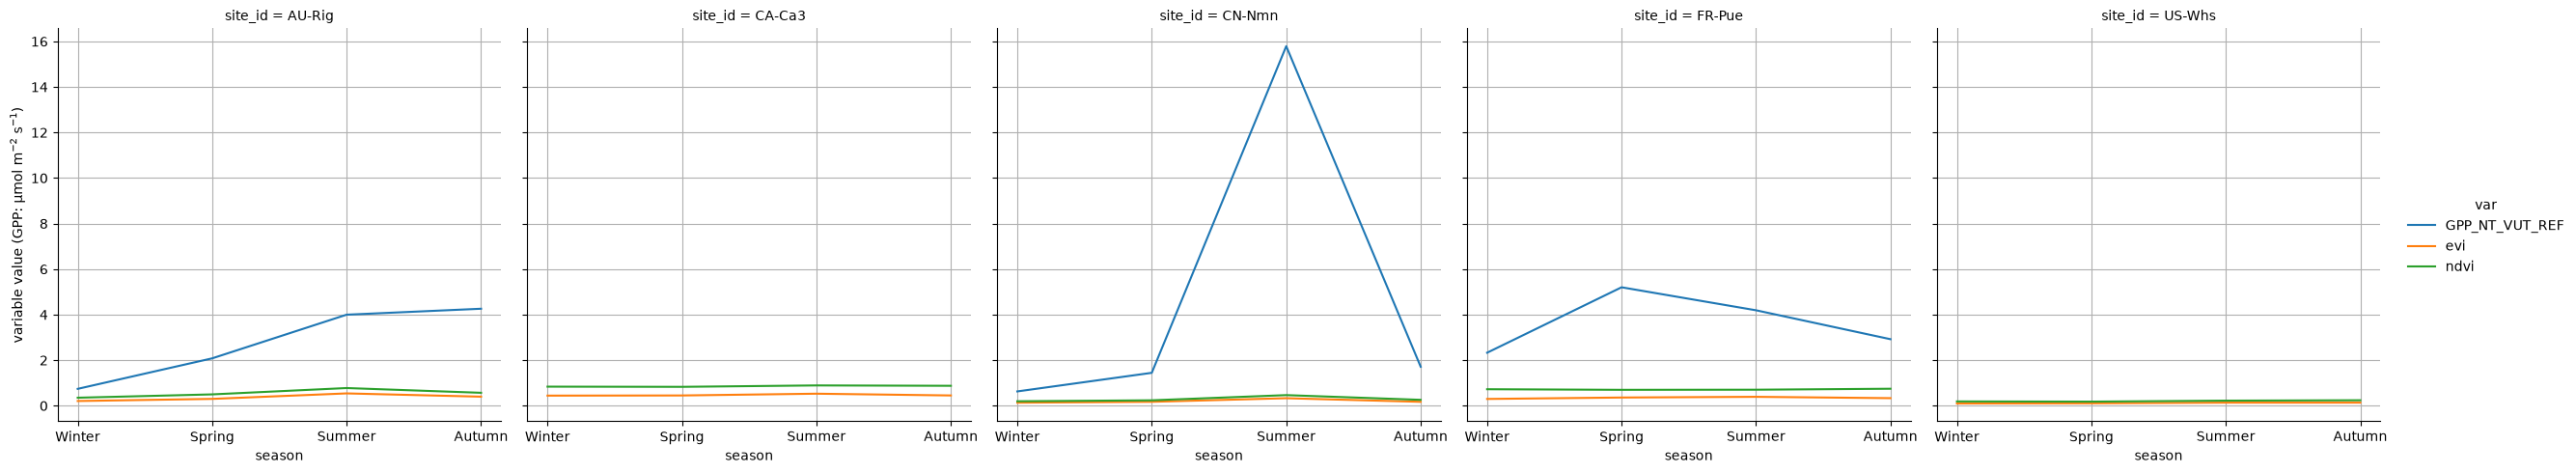

In [227]:
# 16-day means: the scale of the satellite
d16 = site_daily.set_index("date").groupby("site_id")[["GPP_NT_VUT_REF", "evi", "ndvi"]].resample("16D").mean().reset_index()

print("GPP/EVI correlation:")
print(d16.groupby("site_id").apply(lambda g: g["GPP_NT_VUT_REF"].corr(g["evi"])))
print("------------------")
print("GPP/NDVI correlation:")
print(d16.groupby("site_id").apply(lambda g: g["GPP_NT_VUT_REF"].corr(g["ndvi"])))

#Note: what does 'with n stated' mean?

def get_season(doy):
    if 1 <= doy <= 59:      # Jan, Feb
        return 'Winter'
    elif 60 <= doy <= 151:  # Mar, Apr, May
        return 'Spring'
    elif 152 <= doy <= 243: # Jun, Jul, Aug
        return 'Summer'
    elif 244 <= doy <= 334: # Sep, Oct, Nov
        return 'Autumn'
    else:                   # Dec
        return 'Winter'
d16['season'] = d16['date'].dt.day_of_year.apply(get_season)
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
d16['season'] = pd.Categorical(d16['season'], categories=season_order, ordered=True)
d16 = pd.melt(
    d16,
    id_vars=["site_id", "season"],
    value_vars=['GPP_NT_VUT_REF', 'ndvi', 'evi'],
    value_name='value',
    var_name='var'
)
quest = d16.groupby(['site_id', 'season', 'var'])['value'].mean().reset_index()

g = sns.relplot(
    data=quest, x='season', y='value',
    col='site_id', hue='var',
    kind="line"
)
for ax in g.axes.flat:
    ax.grid(True)
g.set_ylabels('variable value (GPP: $\\rm \\mu mol~m^{-2}~s^{-1}$)')
plt.show()

**Observation**:
- *correlations*: the strongest correlation between GPP and EVI is found at site 'CN-Nmn'; the strongest correlation between GPP and NDVI is also found at site 'CN-Nmn'; notably, there is a negative correlation betwenn GPP and EVI at site 'FR-Pue'
- *plot*: due to a lack of GPP data, comparisons of GPP and NDVI/EVI are not possible for all towers of the set; there is no apparent connection for the average season values at any site

----------

## 6\) Scale

Per dataset: pixel vs footprint, and what that means for your answer

**Footprint size**: 100 m - 1 km

**Finer than the footprint**:

| Dataset | Pixel size |
|---------|------------|
| deadtrees.earth | 10 m |

-> *Consequence*: requires averaging (loss of information), but overall definitely better than coarse data

**Similar to footprint**:

| Dataset | Pixel size |
|---------|------------|
| MODIS MOD13Q1 | 250 m |
| SoilGrids | 250 m |
| PlantTraits | 1,000 m |

**Coarser than the footprint**:

| Dataset | Pixel size |
|---------|------------|
| WorldClim (5') | 9,000 m |
| ERA5-Land | 9,000 m |
| ERA5 / Dheed | 28,000 m |

-> *Consequence*: data contained also covers greater surroundings of the tower with potentially very different conditions